# Phase 25B — GT-Free Pre-Refinement Feature Extraction

**Method:** `RA-MedFiLM-BARR` (Resource-Aware MedFiLM with Benefit-Aware Refinement Routing)
**Feature specification revision:** `ra_medfilm_barr_narrowed_v1_2`
**Population:** `ROUTER_DEVELOPMENT` only — **n = 4957**
**Output:** a frozen canonical **202-dimensional** numeric feature cache
**Classification:** `PHASE25B_EXECUTED_EVIDENCE`

### Scope — what this notebook does and does NOT do

This notebook extracts **GT-free, pre-refinement, inference-available** feature vectors from the
**frozen** Phase-21 Global MedFiLM, using the frozen ROI-0.30 geometry. Every feature could be
computed at deployment time from the global model's own output — **no ground truth is read**.

| FORBIDDEN in Phase 25B | status |
|---|---|
| router training | NOT performed |
| `DeltaDice` / paired-gain labels | NOT computed |
| regional refiner forward | NOT performed |
| post-safety model | NOT instantiated |
| `ROUTER_HOLDOUT` feature extraction | NOT performed |
| `ROUTER_HOLDOUT` outcome access | NOT performed |
| VAL feature extraction / evaluation | NOT performed |
| TEST access | ZERO reads |
| Phase 25C / 25D | NOT started |

The only permitted model forward is the **Global MedFiLM replay**, used solely to obtain the three
tap feature maps and the probability map that those maps are pooled from.

## §2 — Bootstrap, imports and artifact paths

In [1]:
import hashlib, json, sys
from pathlib import Path
import numpy as np
import pandas as pd

ROOT = Path(r"D:/Softfors/jup")
sys.path.insert(0, str(ROOT))
AUD = ROOT / "reports" / "audits"
TAB = ROOT / "reports" / "tables"
FIGD = ROOT / "reports" / "figures" / "phase25b_gt_free_features"
CACHE = ROOT / "data_cache" / "phase25b_barr_pre_refinement_features_v1_2"
ROI030 = ROOT / "data_cache" / "phase25a_barr_roi030_cache"

def _j(p):
    p = Path(p)
    return json.loads(p.read_text(encoding="utf-8")) if p.exists() else {}

def sty(df, key, fmts=None):
    fmts = fmts or {}
    return (df.style.format(fmts).set_uuid("p25b-" + key)
            .set_table_styles([{"selector": "th", "props": [("text-align", "left")]}]))

assertions = []
def chk(name, ok, detail=None):
    assertions.append((name, bool(ok), detail))
    print(("[PASS] " if ok else "[FAIL] ") + name + ("" if detail is None else f" :: {detail}"))

def fig(name, caption):
    from IPython.display import Image, display, Markdown
    p = FIGD / name
    display(Markdown(f"**{caption}**"))
    if p.exists():
        display(Image(filename=str(p)))
    else:
        print("MISSING FIGURE:", name)
print("Phase 25B notebook bootstrap ok")

Phase 25B notebook bootstrap ok


## §3 — Authorized predecessor binding

In [2]:
bind = {
  "authored_v1_2": _j(AUD / "phase25b_phase24_v1_2_binding.json"),
  "phase25a": _j(AUD / "phase25b_phase25a_binding.json"),
}
for k, v in bind.items():
    print(f"--- {k} ---")
    print(json.dumps({kk: vv for kk, vv in v.items()
                      if kk not in ("groups",)}, indent=1)[:900])
chk("phase24 v1.2 binding PASS",
    bind["authored_v1_2"].get("verdict") == "PHASE25B_PHASE24_V1_2_BINDING_PASS")
chk("phase25a binding PASS",
    bind["phase25a"].get("verdict") == "PHASE25B_PHASE25A_BINDING_PASS")
chk("superseded v1.1 spec recorded as blocking",
    bind["authored_v1_2"].get("extraction_blocked_under_v1_1") is True)

--- authored_v1_2 ---
{
 "artifact": "phase25b_phase24_v1_2_binding",
 "phase": "25B",
 "purpose": "bind the AUTHORITATIVE Phase24 v1.2 router-feature specification (supersedes the v1.1 spec that blocked the first 25B attempt)",
 "spec_revision": "ra_medfilm_barr_narrowed_v1_2",
 "superseded_revision": "ra_medfilm_barr_narrowed_v1_1",
 "phase24_notebook_sha256": "9d62384e8afa2f35e985eac219711df0334fbfe72c33c0edd29ff3f4897d4027",
 "phase24_notebook_sha_exact": true,
 "phase24_v1_2_completion_verdict": "RF1_RF2_RF3_D1_D2_RESOLVED",
 "all_feature_definitions_resolved": true,
 "all_threshold_roles_resolved": true,
 "supervisor_decisions_recorded": [
  "D1",
  "D2"
 ],
 "features_fully_defined_before_extraction": true,
 "extraction_blocked_under_v1_1": true,
 "blocked_attempt_preserved": "reports/audits/phase25b_phase24_feature_spec_binding.json",
 "verdict": "PHASE25B_PHASE24_V1_2_BINDING_PASS",
 "generated_utc":
--- phase25a ---
{
 "artifact": "phase25b_phase25a_binding",
 "phase": "25B",

## §4 — Fail-closed re-entry gate

In [3]:
rg = _j(AUD / "phase25b_reentry_gate.json")
print("verdict      :", rg.get("verdict"))
print("checks passed:", rg.get("n_checks") - rg.get("n_failed", 0), "/", rg.get("n_checks"))
print("failed       :", rg.get("n_failed"))
chk("re-entry gate PASS", rg.get("verdict") == "PHASE25B_REENTRY_GATE_PASS")
chk("re-entry gate zero failures", rg.get("n_failed") == 0)
chk("re-entry gate 33/33", rg.get("n_checks") == 33 and rg.get("n_failed") == 0)
fails = [c for c in rg.get("checks", []) if not c.get("passed")]
for f in fails:
    print("  FAILED:", f.get("check"), "->", f.get("detail"))

verdict      : PHASE25B_REENTRY_GATE_PASS
checks passed: 33 / 33
failed       : 0
[PASS] re-entry gate PASS
[PASS] re-entry gate zero failures
[PASS] re-entry gate 33/33


## §5 — Frozen model binding

Only the frozen Phase-21 **Global MedFiLM** is evaluated.  It is placed in `eval()` mode, all
parameters have `requires_grad = False`, and every forward pass runs under `torch.no_grad()` with
`torch.amp.autocast`.  **No** regional refiner, benefit router or post-safety module is
instantiated anywhere in this phase.

In [4]:
gc = _j(AUD / "phase25b_global_checkpoint_binding.json")
print("checkpoint path :", gc.get("global_checkpoint_path"))
print("checkpoint sha  :", gc.get("global_checkpoint_sha256"))
print("sha exact       :", gc.get("global_checkpoint_sha_exact"))
print("parameters      :", gc.get("global_model_parameters"))
print("eval mode       :", gc.get("model_eval_mode"))
print("all frozen      :", gc.get("all_parameters_frozen"))
print("inference only  :", gc.get("inference_only"))
chk("global checkpoint binding PASS",
    gc.get("verdict") == "PHASE25B_GLOBAL_CHECKPOINT_BINDING_PASS")
chk("global checkpoint SHA exact", gc.get("global_checkpoint_sha_exact") is True)
chk("model eval + frozen + inference-only",
    gc.get("model_eval_mode") and gc.get("all_parameters_frozen")
    and gc.get("inference_only"))
chk("global model parameters == 3523001", gc.get("global_model_parameters") == 3523001)

checkpoint path : checkpoints/phase21_global_medfilm_fourdomain_seed42_clean_v3/best.pt
checkpoint sha  : 286689fdd5c63ad75a383151d267af8b476e7a98327632de292ce6ed5b5ba1b7
sha exact       : True
parameters      : 3523001
eval mode       : True
all frozen      : True
inference only  : True
[PASS] global checkpoint binding PASS
[PASS] global checkpoint SHA exact
[PASS] model eval + frozen + inference-only
[PASS] global model parameters == 3523001


## §6 — ROI-0.30 geometry binding, and why **not** ROI-0.50

ROI geometry comes from the canonical **ROI-0.30** cache.  The two thresholds play different
semantic roles and are never conflated:

* **ROI PROPOSAL threshold = 0.30** → predicted foreground → bbox → `ACTION_AVAILABLE`
* **SEGMENTATION OUTPUT threshold = 0.50** → inherited; used only for probability-margin descriptors

In [5]:
rb = _j(AUD / "phase25b_roi030_cache_binding.json")
print("canonical cache     :", rb.get("roi030_cache"))
print("noncanonical cache  :", rb.get("roi050_cache"), "used:", rb.get("roi050_used"))
print("roi030 rows         :", rb.get("roi030_rows"))
print("== ROUTER_DEVELOPMENT:", rb.get("roi030_rows_equal_router_development"))
print("holdout overlap     :", rb.get("holdout_overlap"))
print("per-domain          :", rb.get("per_domain"))
chk("ROI-0.30 cache binding PASS",
    rb.get("verdict") == "PHASE25B_ROI030_CACHE_BINDING_PASS")
chk("ROI-0.30 is canonical, ROI-0.50 is not",
    rb.get("roi030_is_canonical") is True and rb.get("roi050_is_canonical") is False)
chk("ROI-0.50 not used", rb.get("roi050_used") is False)
chk("ROI030 rows == 4957 and == ROUTER_DEVELOPMENT",
    rb.get("roi030_rows") == 4957 and rb.get("roi030_rows_equal_router_development") is True)
chk("zero holdout overlap in ROI030", rb.get("holdout_overlap") == 0)

canonical cache     : data_cache/phase25a_barr_roi030_cache
noncanonical cache  : data_cache/phase25a_global_cache used: False
roi030 rows         : 4957
== ROUTER_DEVELOPMENT: True
holdout overlap     : 0
per-domain          : {'BUSI': 512, 'ISIC': 2173, 'KUB': 1680, 'KVASIR': 592}
[PASS] ROI-0.30 cache binding PASS
[PASS] ROI-0.30 is canonical, ROI-0.50 is not
[PASS] ROI-0.50 not used
[PASS] ROI030 rows == 4957 and == ROUTER_DEVELOPMENT
[PASS] zero holdout overlap in ROI030


## §7 — Extraction population: `ROUTER_DEVELOPMENT` only

The feature cache contains **exactly** the 4957 `ROUTER_DEVELOPMENT` rows of the frozen split.
No `ROUTER_HOLDOUT`, no VAL, no TEST row is extracted.

In [6]:
meta = pd.read_csv(CACHE / "metadata.csv")
sm = pd.read_csv(AUD / "phase24_router_split_manifest.csv")
dev = sm[sm["split_role"] == "ROUTER_DEVELOPMENT"]
hold = sm[sm["split_role"] == "ROUTER_HOLDOUT"]
popt = pd.read_csv(TAB / "phase25b_extraction_population.csv")
vc = meta["domain"].value_counts().reindex(["BUSI", "ISIC", "KUB", "KVASIR"])
print("cache rows              :", len(meta))
print("ROUTER_DEVELOPMENT rows :", len(dev))
print("ROUTER_HOLDOUT rows     :", len(hold))
print("per-domain              :"); print(vc.to_string())
chk("cache rows == 4957", len(meta) == 4957)
chk("sample ids exactly == ROUTER_DEVELOPMENT",
    set(meta["sample_id"]) == set(dev["sample_id"]))
chk("zero ROUTER_HOLDOUT ids in cache",
    len(set(meta["sample_id"]) & set(hold["sample_id"])) == 0)
chk("four domains present", set(vc.index) == {"BUSI", "ISIC", "KUB", "KVASIR"})
chk("population table total == 4957",
    int(popt[popt["domain"] == "TOTAL"]["n"].iloc[0]) == 4957)
display(sty(pd.DataFrame({"rows": vc}), "pop", {}))

cache rows              : 4957
ROUTER_DEVELOPMENT rows : 4957
ROUTER_HOLDOUT rows     : 875
per-domain              :
domain
BUSI       512
ISIC      2173
KUB       1680
KVASIR     592
[PASS] cache rows == 4957
[PASS] sample ids exactly == ROUTER_DEVELOPMENT
[PASS] zero ROUTER_HOLDOUT ids in cache
[PASS] four domains present
[PASS] population table total == 4957


,rows
domain,
BUSI,512
ISIC,2173
KUB,1680
KVASIR,592


## §8 — Global forward equivalence to the canonical probability cache

The replayed probability map must be **numerically equivalent** to the frozen canonical
`prob512.npy` (float32).  Requirement: `max_abs ≤ 1e-6`, otherwise the phase is BLOCKED.

The exact canonical forward path is reproduced: identical frozen checkpoint, identical
aspect-preserving preprocessing, identical `no_grad + torch.amp.autocast` batched forward, and
identical batch composition.

In [7]:
eq = _j(AUD / "phase25b_global_forward_equivalence.json")
print("reference       :", eq.get("reference"))
print("n compared      :", eq.get("n_samples_compared"))
print("tolerance       :", eq.get("tolerance"))
print("max_abs         :", eq.get("max_abs_difference"))
print("mean_abs        :", eq.get("mean_abs_difference"))
print("n exceeding tol :", eq.get("n_exceeding_tolerance"))
print("byte identical  :", eq.get("byte_identical_achieved"))
print("verdict         :", eq.get("verdict"))
chk("global forward equivalence PASS",
    eq.get("verdict") == "PHASE25B_GLOBAL_FORWARD_EQUIVALENCE_PASS")
chk("max_abs <= 1e-6",
    eq.get("max_abs_difference") is not None and eq.get("max_abs_difference") <= 1e-6)
chk("n exceeding tolerance == 0", eq.get("n_exceeding_tolerance") == 0)
chk("all 4957 compared", eq.get("n_samples_compared") == 4957)

reference       : data_cache/phase25a_barr_roi030_cache/<DOMAIN>/prob512.npy (float32)
n compared      : 4957
tolerance       : 1e-06
max_abs         : 0.0
mean_abs        : 0.0
n exceeding tol : 0
byte identical  : True
verdict         : PHASE25B_GLOBAL_FORWARD_EQUIVALENCE_PASS
[PASS] global forward equivalence PASS
[PASS] max_abs <= 1e-6
[PASS] n exceeding tolerance == 0
[PASS] all 4957 compared


## §9 — Feature taps

Three internal activation maps of the frozen Global MedFiLM are tapped with inference-only
`register_forward_hook` output readers.  The hooks never modify the graph — this is proven by the
equivalence audit in §8.

In [8]:
hk = _j(AUD / "phase25b_global_feature_hook_audit.json")
chk("global feature hook audit PASS",
    hk.get("verdict") == "PHASE25B_GLOBAL_FEATURE_HOOK_AUDIT_PASS")
chk("hook does not modify the graph", hk.get("hook_modifies_graph") is False)
chk("no leaked hook handles", hk.get("leaked_handles") == 0)
chk("probability output unchanged by hooks",
    hk.get("probability_output_unchanged_by_hooks") is True)
taps = hk.get("taps", {})
for t, d in taps.items():
    print(f"{t:9s} native_channels={d['native_channels']:>4} grid={d['feature_grid']}")
chk("three taps: bridge / decoder2 / decoder1", set(taps) == {"bridge", "decoder2", "decoder1"})

[PASS] global feature hook audit PASS
[PASS] hook does not modify the graph
[PASS] no leaked hook handles
[PASS] probability output unchanged by hooks
bridge    native_channels= 256 grid=32
decoder2  native_channels=  48 grid=256
decoder1  native_channels=  24 grid=512
[PASS] three taps: bridge / decoder2 / decoder1


## §10 — Channel-adaptive deterministic reduction to width 32

`DETERMINISTIC_CHANNEL_ADAPTIVE_AVG_POOL_1D_V1`:

`start_j = floor(j·C/32)`, `end_j = ceil((j+1)·C/32)`, `z[j] = mean(v[start_j:end_j])`

For `C < 32` the bins overlap; for `C ≥ 32` they are disjoint.  **Zero** trainable parameters —
no projection, no PCA, no random projection, no SVD, no truncation.

In [9]:
red = _j(AUD / "phase25b_feature_reduction_audit.json")
print("operation        :", red.get("operation"))
print("output width K   :", red.get("output_width_K"))
print("trainable params :", red.get("trainable_parameters"))
print("forbidden ops    :", red.get("forbidden_ops_used"))
for t, d in red.get("taps", {}).items():
    print(f"  {t:9s} C={d['native_width']:>4} bins={d['bins']} "
          f"overlap={d['overlapping_bins_expected']} covers_all={d['covers_all_channels']}")
chk("reduction audit PASS",
    red.get("verdict") == "PHASE25B_FEATURE_REDUCTION_PASS")
chk("zero trainable params in reduction", red.get("trainable_parameters") == 0)
chk("no forbidden reduction ops", not red.get("forbidden_ops_used"))
chk("every bin covers all native channels",
    all(d["covers_all_channels"] for d in red.get("taps", {}).values()))
chk("overlap exactly where C < 32",
    all((d["native_width"] < 32) == d["overlapping_bins_expected"]
        for d in red.get("taps", {}).values()))

operation        : DETERMINISTIC_CHANNEL_ADAPTIVE_AVG_POOL_1D_V1
output width K   : 32
trainable params : 0
forbidden ops    : []
  bridge    C= 256 bins=32 overlap=False covers_all=True
  decoder2  C=  48 bins=32 overlap=False covers_all=True
  decoder1  C=  24 bins=32 overlap=True covers_all=True
[PASS] reduction audit PASS
[PASS] zero trainable params in reduction
[PASS] no forbidden reduction ops
[PASS] every bin covers all native channels
[PASS] overlap exactly where C < 32


## §11 — ROI → feature-grid mapping

The ROI box (in 512-canvas coordinates) is mapped to each tap's feature grid by the half-open rule
`start = floor`, `end = ceil`, clipped to the grid. External padding contributes **no** cell. Every
mapped ROI must contain ≥ 1 cell.

In [10]:
mp = _j(AUD / "phase25b_roi_feature_mapping_audit.json")
print("convention :", mp.get("coordinate_convention"))
print("start/end  :", mp.get("start_rule"), "/", mp.get("end_rule"))
print("clip       :", mp.get("clip"))
print("rows verified:", mp.get("rows_verified"))
print("empty mapped ROIs:", mp.get("empty_mapped_roi_count"))
print("bridge cells min/max:", mp.get("bridge_grid_cells_min"), mp.get("bridge_grid_cells_max"))
chk("ROI mapping audit PASS",
    mp.get("verdict") == "PHASE25B_ROI_FEATURE_MAPPING_PASS")
chk("no empty mapped ROI", mp.get("empty_mapped_roi_count") == 0)
chk("external padding contributes no cells",
    mp.get("external_padding_contributes_no_cells") is True)
chk("all 4957 rows verified", mp.get("rows_verified") == 4957)

convention : HALF_OPEN
start/end  : floor / ceil
clip       : True
rows verified: 4957
empty mapped ROIs: 0
bridge cells min/max: 1 1024
[PASS] ROI mapping audit PASS
[PASS] no empty mapped ROI
[PASS] external padding contributes no cells
[PASS] all 4957 rows verified


## §12 — Ten GT-free scalar descriptors (with the D1 correction)

Ten scalars follow the six 32-D deep groups.  `predicted_roi_area_fraction` uses the
**supervisor-corrected** D1 definition on the clipped in-canvas ROI:

`w_in = max(0, min(512, x1) − max(0, x0))`, `h_in` likewise, `area_fraction = w_in·h_in / 512²`

This supersedes the old `crop_side_pixels²/512²`, which could exceed 1 whenever the crop window ran
past the canvas.  `predicted_roi_side` may legitimately exceed 512.

In [11]:
sc = _j(AUD / "phase25b_scalar_feature_semantics.json")
chk("scalar semantics audit present", sc.get("n_scalars") == 10)
chk("all threshold roles resolved", sc.get("unresolved_threshold_roles") == 0)
chk("scalars use no GT", sc.get("uses_GT") is False)
d1 = _j(AUD / "phase25b_d1_area_fraction_audit.json")
print("D1 definition   :", d1.get("definition"))
print("superseded      :", d1.get("superseded_formula"),
      "used:", d1.get("superseded_formula_used"))
print("area range      :", d1.get("feature_range"))
print("rows > 1        :", d1.get("rows_exceeding_1"))
print("side max        :", d1.get("predicted_roi_side_max"),
      "rows>512:", d1.get("predicted_roi_side_rows_gt512"))
print("recompute max diff:", d1.get("max_abs_recompute_diff"))
chk("D1 area fraction PASS", d1.get("verdict") == "PHASE25B_D1_AREA_FRACTION_PASS")
chk("area fraction in [0,1], zero rows > 1", d1.get("rows_exceeding_1") == 0)
chk("superseded D1 formula not used", d1.get("superseded_formula_used") is False)
chk("area recomputation matches feature",
    d1.get("recomputed_matches_feature") is True)
chk("roi side may exceed 512", d1.get("predicted_roi_side_rows_gt512", 0) > 0)
display(sty(pd.DataFrame(sc.get("scalars", [])), "scalars",
            {"feature_index": "{:.0f}"}))

[PASS] scalar semantics audit present
[PASS] all threshold roles resolved
[PASS] scalars use no GT
D1 definition   : w_in = max(0, min(512,x1)-max(0,x0)); h_in = max(0, min(512,y1)-max(0,y0)); predicted_roi_area_fraction = w_in*h_in/(512*512)
superseded      : crop_side_pixels^2 / 512^2 used: False
area range      : {'min': 1.52587890625e-05, 'max': 1.0, 'mean': 0.5126122526038384}
rows > 1        : 0
side max        : 768.0 rows>512: 1257
recompute max diff: 0.0
[PASS] D1 area fraction PASS
[PASS] area fraction in [0,1], zero rows > 1
[PASS] superseded D1 formula not used
[PASS] area recomputation matches feature
[PASS] roi side may exceed 512


,feature_index,feature_name,threshold_role,threshold_value,formula,units,input_source,dtype,uses_GT,expected_range,external_padding_excluded,superseded_formula,superseded_status,may_exceed_512
0,192,entropy_proxy_mean,THRESHOLD_FREE,nan,"mean over all N pixels of -[q*ln q + (1-q)*ln(1-q)]/ln 2, q = clip(P, 1e-7, 1-1e-7)","dimensionless in [0,1]",P (global probability map),float32,False,nan,nan,nan,nan,nan
1,193,frac_prob_within_0p05_of_boundary,SEGMENTATION_OUTPUT_PROBABILITY_BOUNDARY,0.500000,(1/N) * sum 1[|P - 0.50| <= 0.05],"fraction in [0,1]",P,float32,False,nan,nan,nan,nan,nan
2,194,frac_prob_within_0p02_of_boundary,SEGMENTATION_OUTPUT_PROBABILITY_BOUNDARY,0.500000,(1/N) * sum 1[|P - 0.50| <= 0.02],"fraction in [0,1]",P,float32,False,nan,nan,nan,nan,nan
3,195,mean_boundary_margin,SEGMENTATION_OUTPUT_PROBABILITY_BOUNDARY,0.500000,mean over all N pixels of |P - 0.50| (NOT negated),"probability distance in [0,0.5]",P,float32,False,nan,nan,nan,nan,nan
4,197,pred_foreground_pixels,ROI_PROPOSAL,0.300000,sum M_roi where M_roi = 1[P >= 0.30],pixels on the 512x512 canvas,P,float32,False,nan,nan,nan,nan,nan
5,196,pred_foreground_fraction,ROI_PROPOSAL,0.300000,pred_foreground_pixels / N,"fraction in [0,1]",P,float32,False,nan,nan,nan,nan,nan
6,198,pred_roi_exists,ROI_PROPOSAL,0.300000,1.0 if pred_foreground_pixels > 0 else 0.0,binary indicator,P,float32,False,nan,nan,nan,nan,nan
7,199,pred_empty,ROI_PROPOSAL,0.300000,1.0 - pred_roi_exists,binary indicator,P,float32,False,nan,nan,nan,nan,nan
8,200,predicted_roi_area_fraction,ROI_PROPOSAL,0.300000,"w_in = max(0, min(512, x1) - max(0, x0)); h_in = max(0, min(512, y1) - max(0, y0)); predicted_roi_area_fraction = w_in * h_in / (512 * 512)",fraction of the native 512x512 canvas (clipped in-canvas ROI),ROI030 crop metadata,float32,False,"[0,1]",True,crop_side_pixels^2 / (512^2),SUPERSEDED_PRE_EXECUTION_SPEC_FORMULA__NOT_USED_FOR_PHASE25B,nan
9,201,predicted_roi_side,ROI_PROPOSAL,0.300000,canonical cache field crop_side_pixels (before resize to 256x256),pixels on the 512 canvas (crop support incl. padding; may exceed 512),ROI030 crop metadata,float32,False,nan,nan,nan,nan,True


## §13 — Exact 202-D ordering

Indices `0..191` are the six 32-D deep groups (bridge_global, bridge_roi, decoder2_global,
decoder2_roi, decoder1_global, decoder1_roi).  Indices `192..201` are the ten scalars in the frozen
order.  `task_id` is **not** part of the vector — no task embedding is embedded here.

In [12]:
fo = _j(AUD / "phase25b_feature_order_audit.json")
print("numeric dims :", fo.get("numeric_dimensions"))
print("deep dims    :", fo.get("deep_dimensions"))
print("scalar dims  :", fo.get("scalar_dimensions"))
print("task embedding appended:", fo.get("task_embedding_appended"))
print("group offsets:"); print(json.dumps(fo.get("group_offsets"), indent=1)[:600])
chk("feature order audit exact",
    fo.get("verdict") == "PHASE25B_FEATURE_ORDER_EXACT")
chk("numeric_dim == 202", fo.get("numeric_dimensions") == 202)
chk("names match frozen order", fo.get("names_match_frozen_order") is True)
chk("no task embedding in the vector", fo.get("task_embedding_appended") is False)

numeric dims : 202
deep dims    : 192
scalar dims  : 10
task embedding appended: False
group offsets:
{
 "groups": [
  {
   "name": "bridge_global",
   "tap": "bridge",
   "scope": "GLOBAL",
   "start": 0,
   "stop": 32,
   "dim": 32
  },
  {
   "name": "bridge_roi",
   "tap": "bridge",
   "scope": "ROI",
   "start": 32,
   "stop": 64,
   "dim": 32
  },
  {
   "name": "decoder2_global",
   "tap": "decoder2",
   "scope": "GLOBAL",
   "start": 64,
   "stop": 96,
   "dim": 32
  },
  {
   "name": "decoder2_roi",
   "tap": "decoder2",
   "scope": "ROI",
   "start": 96,
   "stop": 128,
   "dim": 32
  },
  {
   "name": "decoder1_global",
   "tap": "decoder1",
   "scope": "GLOBAL",
   "start": 128,
  
[PASS] feature order audit exact
[PASS] numeric_dim == 202
[PASS] names match frozen order
[PASS] no task embedding in the vector


## §14 — Task metadata stored separately (no patient ID, no GT)

In [13]:
cols = list(meta.columns)
print("metadata columns:", cols)
forbidden = [c for c in cols if any(t in c.lower()
             for t in ("patient", "mask", "gt_", "dice", "gain", "class", "fraction"))]
chk("no forbidden metadata columns", not forbidden, forbidden)
chk("task_id present and separate", "task_id" in cols)
chk("domain / outer_fold present", "domain" in cols and "outer_fold" in cols)
chk("feature_row_index present", "feature_row_index" in cols)
display(meta.head(5))

metadata columns: ['feature_row_index', 'sample_id', 'task_id', 'domain', 'outer_fold', 'action_available', 'predicted_roi_side']
[PASS] no forbidden metadata columns :: []
[PASS] task_id present and separate
[PASS] domain / outer_fold present
[PASS] feature_row_index present


,feature_row_index,sample_id,task_id,domain,outer_fold,action_available,predicted_roi_side
0,0,0075dcb0e337263eff441a6979397143,1,BUSI,fold0,1,434.0
1,1,0076d60041fe324b4f16cd39458691a0,1,BUSI,fold1,1,197.0
2,2,009868e61723f249e74bcfa14dc1aa30,1,BUSI,fold1,1,246.0
3,3,00a0c07e2060340164ebc605b3bf1746,1,BUSI,fold1,1,390.0
4,4,00f8ec946ef6890d99b06c50af6b431a,1,BUSI,fold1,1,247.0


## §15 — Cache on disk

In [14]:
man = _j(CACHE / "cache_manifest.json")
print(json.dumps(man, indent=1)[:1200])
chk("cache manifest present", bool(man))
chk("features.npy present", (CACHE / "features.npy").exists())
chk("metadata.csv present", (CACHE / "metadata.csv").exists())
chk("feature_schema.csv present", (CACHE / "feature_schema.csv").exists())

{
 "artifact": "phase25b_feature_cache_manifest",
 "phase": "25B",
 "classification": "CANONICAL_PHASE25B_GT_FREE_FEATURES",
 "method": "RA-MedFiLM-BARR",
 "feature_spec_revision": "ra_medfilm_barr_narrowed_v1_2",
 "population": "ROUTER_DEVELOPMENT only",
 "population_n": 4957,
 "matrix_shape": [
  4957,
  202
 ],
 "matrix_dtype": "float32",
 "deep_dim": 192,
 "scalar_dim": 10,
 "numeric_dim": 202,
 "task_id_persisted": true,
 "task_embedding_generated": false,
 "feature_spec_reduction_op": "DETERMINISTIC_CHANNEL_ADAPTIVE_AVG_POOL_1D_V1",
 "threshold_semantics": {
  "ROI_PROPOSAL": 0.3,
  "SEGMENTATION_OUTPUT": 0.5
 },
 "phase24_notebook_sha256": "9d62384e8afa2f35e985eac219711df0334fbfe72c33c0edd29ff3f4897d4027",
 "phase21_global_checkpoint_sha256": "286689fdd5c63ad75a383151d267af8b476e7a98327632de292ce6ed5b5ba1b7",
 "phase25a_roi030_cache_manifest_sha256": "cad302059231d70cbd1c9dd8058c9f0e6b121a3f87ac9c4d120707ed0244b0d8",
 "split_manifest_sha256": "b5da52d6220ef9b59b4ba70d0b403b38bf5

## §16 — Cache integrity

In [15]:
ci = _j(AUD / "phase25b_feature_cache_integrity.json")
feats = np.load(CACHE / "features.npy")
print("shape  :", feats.shape, "dtype:", feats.dtype)
print("nan    :", ci.get("nan_count"), "inf:", ci.get("inf_count"))
print("unique ids:", ci.get("unique_sample_ids"))
print("== ROUTER_DEVELOPMENT:", ci.get("sample_ids_equal_router_development"))
print("holdout overlap:", ci.get("holdout_overlap"))
print("feature selection applied:", ci.get("feature_selection_applied"))
print("features sha:", ci.get("matrix_sha256"))
chk("cache integrity PASS",
    ci.get("verdict") == "PHASE25B_FEATURE_CACHE_INTEGRITY_PASS")
chk("shape == (4957, 202)", feats.shape == (4957, 202))
chk("dtype float32", str(feats.dtype) == "float32")
chk("no NaN", ci.get("nan_count") == 0)
chk("no Inf", ci.get("inf_count") == 0)
chk("ids == ROUTER_DEVELOPMENT", ci.get("sample_ids_equal_router_development") is True)
chk("no feature selection applied", ci.get("feature_selection_applied") is False)

shape  : (4957, 202) dtype: float32
nan    : 0 inf: 0
unique ids: 4957
== ROUTER_DEVELOPMENT: True
holdout overlap: 0
feature selection applied: False
features sha: 9c241963b54f23de1c9671ff6670dde7d6f7e2510869ef5ebc1baf3f7c833e0a
[PASS] cache integrity PASS
[PASS] shape == (4957, 202)
[PASS] dtype float32
[PASS] no NaN
[PASS] no Inf
[PASS] ids == ROUTER_DEVELOPMENT
[PASS] no feature selection applied


## §17 — Descriptive analysis only

Summary statistics and per-domain summaries.  **No** target correlation, **no** label correlation,
**no** outcome-conditioned analysis — those belong to later phases.

In [16]:
ss = pd.read_csv(TAB / "phase25b_feature_summary_statistics.csv")
sd = pd.read_csv(TAB / "phase25b_feature_summary_by_domain.csv")
display(sty(ss.head(12), "ss", {}))
display(sty(sd.head(12), "sd", {}))
chk("summary statistics table present", len(ss) > 0)
chk("per-domain summary table present", len(sd) > 0)
chk("no target/label column in tables",
    not any(("dice" in c.lower() or "gain" in c.lower() or "label" in c.lower())
            for c in list(ss.columns) + list(sd.columns)))

,feature_name,mean,std,min,max,median,p01,p05,p95,p99
0,bridge_global_00,0.038019,0.040194,-0.087803,0.303458,0.037675,-0.046194,-0.023506,0.107273,0.149795
1,bridge_global_01,0.043461,0.042750,-0.072144,0.170512,0.041039,-0.044978,-0.024067,0.115729,0.125408
2,bridge_global_02,0.146812,0.043185,0.006285,0.259240,0.154198,0.038286,0.063561,0.205821,0.224353
3,bridge_global_03,0.097084,0.065175,-0.045771,0.326095,0.088014,-0.010001,0.008244,0.212161,0.251298
4,bridge_global_04,0.051797,0.048054,-0.082899,0.267221,0.043818,-0.039794,-0.015128,0.140608,0.188095
5,bridge_global_05,0.057371,0.040614,-0.051458,0.194556,0.052976,-0.021929,-0.003183,0.127635,0.151804
6,bridge_global_06,0.092917,0.049531,-0.029922,0.274547,0.095041,-0.006562,0.011424,0.175483,0.207417
7,bridge_global_07,0.024058,0.054738,-0.094560,0.184578,0.025269,-0.078341,-0.061942,0.120335,0.147710
8,bridge_global_08,0.129612,0.044792,-0.006107,0.257040,0.128023,0.029867,0.057642,0.204178,0.221641
9,bridge_global_09,-0.002778,0.036607,-0.114872,0.185186,-0.007024,-0.076456,-0.056026,0.066733,0.106607


,domain,n,feature_group,mean,std,min,max,p05,p95
0,BUSI,512,bridge_global,0.087341,0.089322,-0.109005,0.367442,-0.043948,0.256406
1,BUSI,512,bridge_roi,0.125824,0.105219,-0.130176,0.667765,-0.024917,0.315474
2,BUSI,512,decoder2_global,1.806882,1.777425,-0.149111,6.683005,-0.096340,5.106516
3,BUSI,512,decoder2_roi,1.954181,1.376475,-0.135776,6.831329,-0.052151,4.323586
4,BUSI,512,decoder1_global,4.893368,5.760944,-0.106411,23.613436,-0.000355,18.632250
5,BUSI,512,decoder1_roi,4.471215,4.077666,-0.076242,21.755592,-0.000979,13.147792
6,ISIC,2173,bridge_global,0.094415,0.085330,-0.115975,0.391087,-0.027676,0.254107
7,ISIC,2173,bridge_roi,0.146424,0.116758,-0.155543,1.090972,-0.007436,0.350381
8,ISIC,2173,decoder2_global,1.614047,1.479812,-0.146848,7.485306,-0.092339,4.620213
9,ISIC,2173,decoder2_roi,1.617548,1.165318,-0.140125,9.310171,-0.074180,3.553264


[PASS] summary statistics table present
[PASS] per-domain summary table present
[PASS] no target/label column in tables


## §18 — Determinism subset audit (64 samples, 16/domain)

A pre-declared 64-sample audit subset (selection independent of feature values and outcomes) is
re-extracted twice under identical inference settings and compared against the frozen cache.  All
4957 rows are **not** re-run.  Because AMP numerics depend on batch membership, the re-run replays
the canonical contiguous batches so each sampled row sits in the same batch as canonically.

In [17]:
det = _j(AUD / "phase25b_feature_determinism.json")
sub = pd.read_csv(TAB / "phase25b_feature_determinism_subset.csv")
print("subset size   :", det.get("subset_size"), "per domain:", det.get("per_domain"))
print("ran all 4957? :", det.get("reran_all_4957"))
print("run1 vs run2  :", det.get("run1_vs_run2"))
print("run1 vs frozen:", det.get("run1_vs_frozen_cache"))
print("verdict       :", det.get("verdict"))
chk("determinism PASS", det.get("verdict") == "PHASE25B_FEATURE_DETERMINISM_PASS")
chk("run1 vs run2 max_abs <= 1e-6",
    det.get("run1_vs_run2", {}).get("max_abs", 9) <= 1e-6)
chk("run1 vs frozen max_abs <= 1e-6",
    det.get("run1_vs_frozen_cache", {}).get("max_abs", 9) <= 1e-6)
chk("all 4957 NOT rerun", det.get("reran_all_4957") is False)
chk("subset is 64 rows, 16/domain",
    len(sub) == 64 and sub["domain"].value_counts().nunique() == 1
    and set(sub["domain"].value_counts().values) == {16})
display(sty(sub.head(8), "sub", {}))

subset size   : 64 per domain: 16
ran all 4957? : False
run1 vs run2  : {'max_abs': 0.0, 'mean_abs': 0.0, 'n_elements_exceeding_tolerance': 0, 'allclose': True}
run1 vs frozen: {'max_abs': 0.0, 'mean_abs': 0.0, 'n_elements_exceeding_tolerance': 0, 'allclose': True}
verdict       : PHASE25B_FEATURE_DETERMINISM_PASS
[PASS] determinism PASS
[PASS] run1 vs run2 max_abs <= 1e-6
[PASS] run1 vs frozen max_abs <= 1e-6
[PASS] all 4957 NOT rerun
[PASS] subset is 64 rows, 16/domain


,audit_index,domain,sample_id,feature_row_index
0,0,BUSI,0075dcb0e337263eff441a6979397143,0
1,1,BUSI,12c236ec1c276f4fb7cf593fba2c718b,34
2,2,BUSI,24b838a0c35b7546711a143945d6608c,68
3,3,BUSI,3759eac568b31cb5dd2b3e21a0e3d375,102
4,4,BUSI,4872bb440d5c5835e997e09f3ecbc473,136
5,5,BUSI,5789e50d30d2af2cf1a3b3742de04253,170
6,6,BUSI,7002b2136c075add808796a1fdd6b173,204
7,7,BUSI,83e0cee9dfafd1c4b89655cf540e015c,238


## §19 — Implementation test suite

In [18]:
ts = _j(AUD / "phase25b_implementation_test_suite.json")
print("verdict :", ts.get("verdict"))
print("passed  :", ts.get("n_passed"), "/", ts.get("n_checks"))
fails = [c for c in ts.get("checks", []) if not c.get("passed")]
for f in fails:
    print("  FAILED:", f.get("check"), "->", f.get("detail"))
chk("implementation tests PASS",
    ts.get("verdict") == "PHASE25B_IMPLEMENTATION_TESTS_PASS")
chk("zero implementation test failures", ts.get("n_failed") == 0)

verdict : PHASE25B_IMPLEMENTATION_TESTS_PASS
passed  : None / 38
[PASS] implementation tests PASS
[PASS] zero implementation test failures


## §20 — Required tables

In [19]:
tab_names = ["phase25b_feature_schema.csv",
             "phase25b_feature_group_summary.csv",
             "phase25b_scalar_feature_definitions.csv",
             "phase25b_feature_summary_statistics.csv",
             "phase25b_feature_summary_by_domain.csv",
             "phase25b_extraction_population.csv",
             "phase25b_feature_cache_inventory.csv",
             "phase25b_feature_determinism_subset.csv"]
present = [t for t in tab_names if (TAB / t).exists()]
print("tables present:", len(present), "/", len(tab_names))
for t in present:
    print("  ", t)
chk("all required tables present", len(present) == len(tab_names),
    [t for t in tab_names if t not in present])

tables present: 8 / 8
   phase25b_feature_schema.csv
   phase25b_feature_group_summary.csv
   phase25b_scalar_feature_definitions.csv
   phase25b_feature_summary_statistics.csv
   phase25b_feature_summary_by_domain.csv
   phase25b_extraction_population.csv
   phase25b_feature_cache_inventory.csv
   phase25b_feature_determinism_subset.csv
[PASS] all required tables present :: []


## §21 — Required figures

n figures: 7 (required 6 + optional 1 )


**feature pipeline**

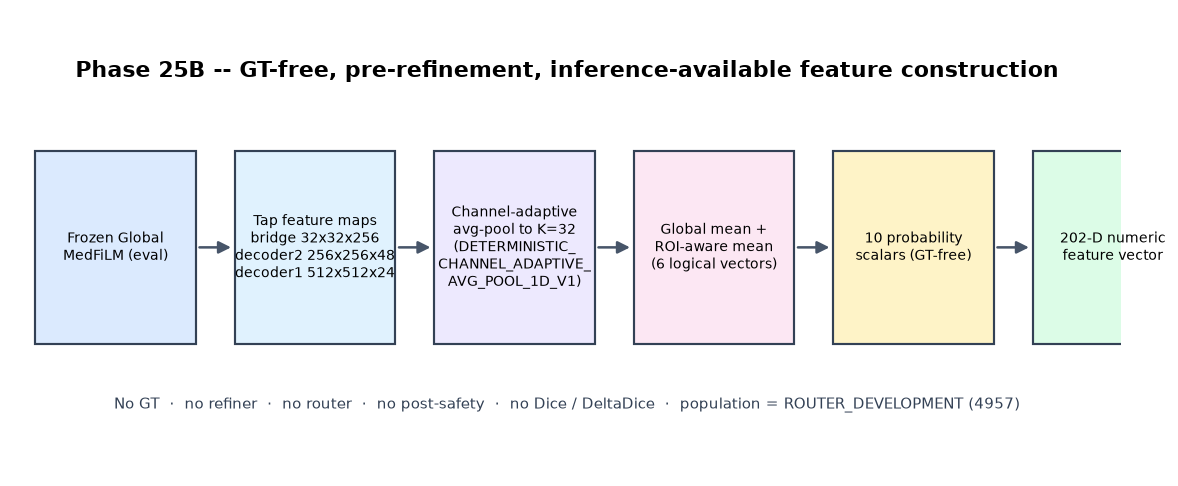

**channel adaptive reduction**

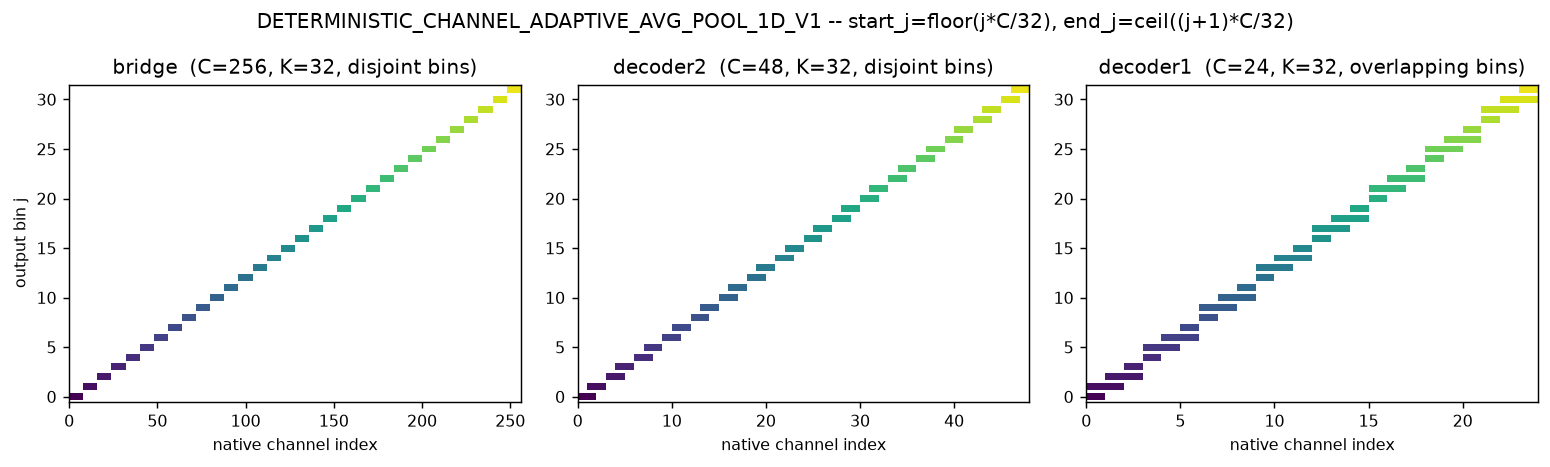

**feature group layout**

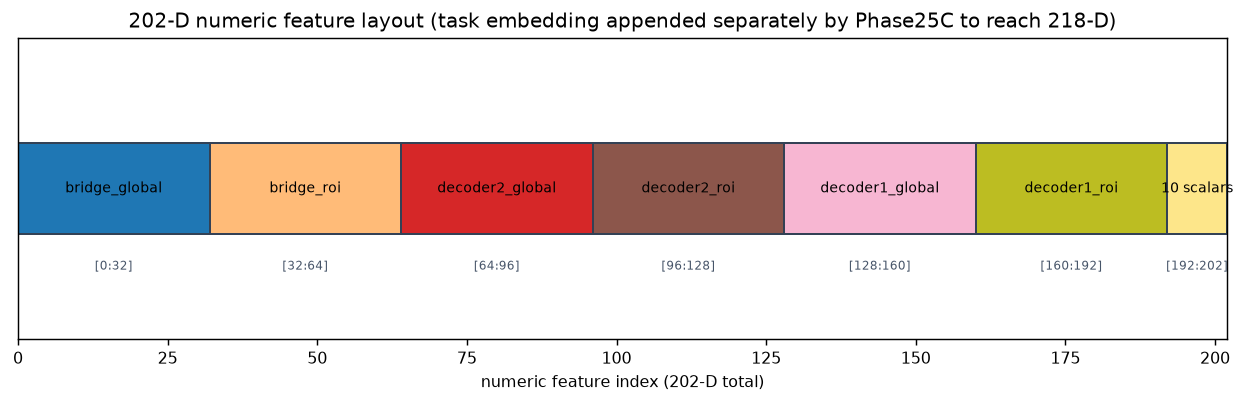

**scalar descriptors**

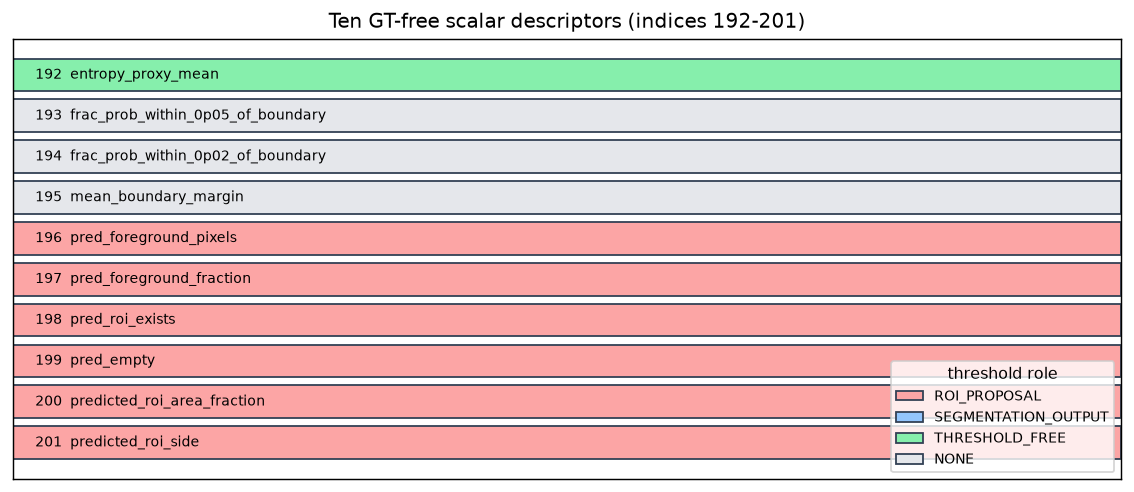

**extraction population**

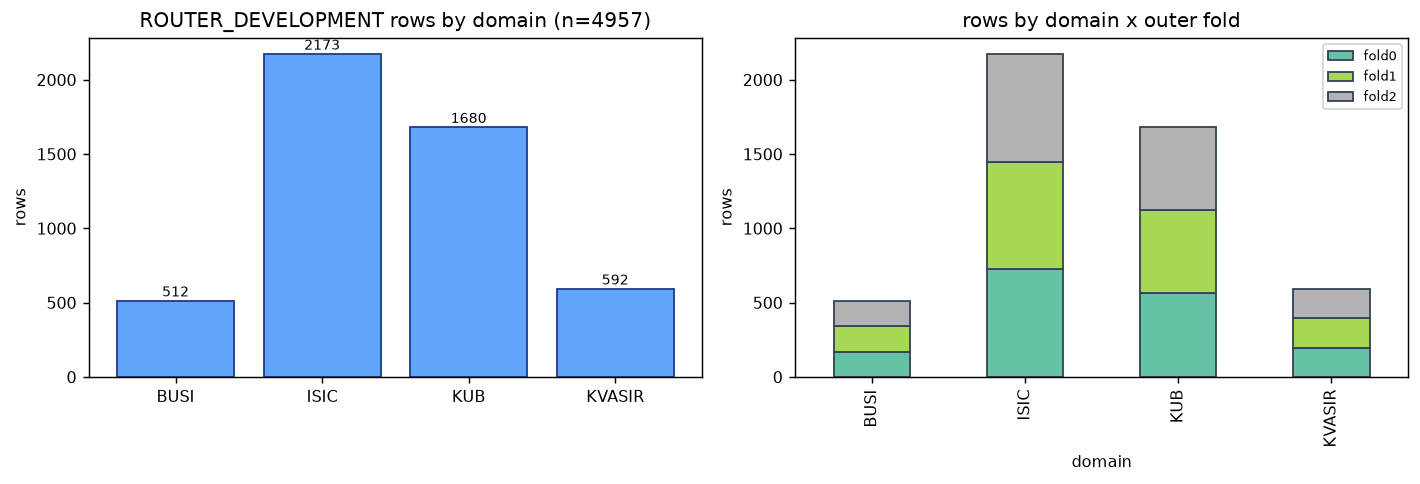

**cache integrity summary**

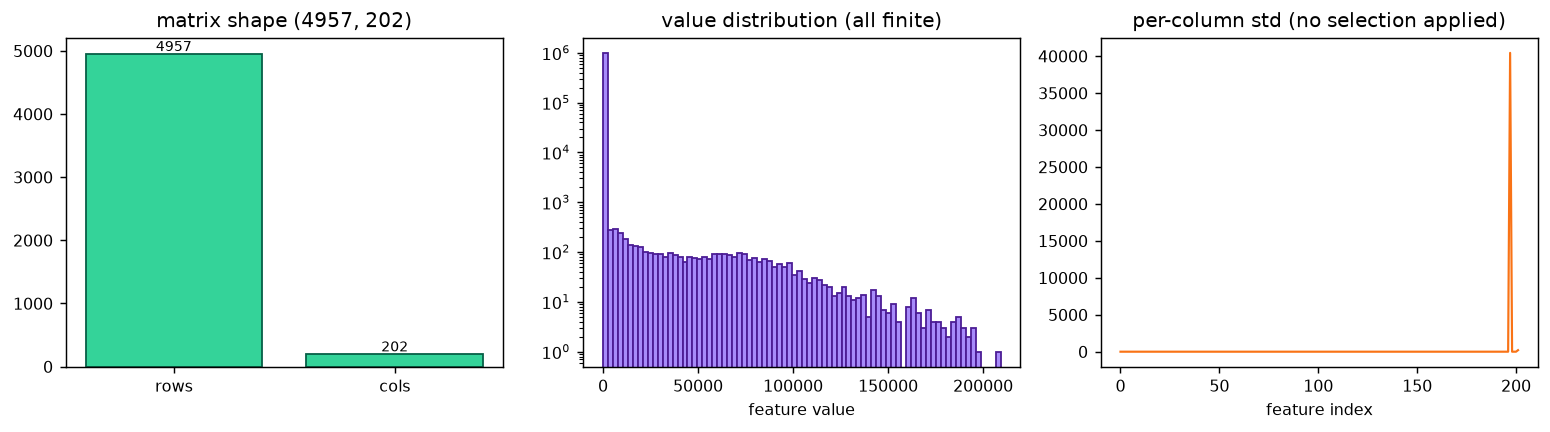

[PASS] figure manifest present
[PASS] at least 6 required figures
[PASS] no experimental results in figures


In [20]:
fm = _j(FIGD / "phase25b_figure_manifest.json")
print("n figures:", fm.get("n_figures"),
      "(required", fm.get("n_required_figures"), "+ optional",
      fm.get("n_optional_figures"), ")")
for name in ["p25b_feature_pipeline.png",
             "p25b_channel_adaptive_reduction.png",
             "p25b_feature_group_layout.png",
             "p25b_scalar_descriptors.png",
             "p25b_extraction_population.png",
             "p25b_cache_integrity_summary.png"]:
    fig(name, name.replace("p25b_", "").replace(".png", "").replace("_", " "))
chk("figure manifest present", bool(fm))
chk("at least 6 required figures", fm.get("n_required_figures", 0) >= 6)
chk("no experimental results in figures",
    fm.get("contains_experimental_results") is False)

## §22 — No-outcome / no-GT / scope guards

Confirms the phase read no ground truth, computed no segmentation metric, instantiated no refiner or
router, and performed no post-safety step.

In [21]:
ng = _j(AUD / "phase25b_no_gt_leakage_audit.json")
sg = _j(AUD / "phase25b_scope_guard.json")
for k in ("gt_masks_read_for_feature_construction", "dice_computed", "deltadice_computed",
          "iou_computed", "refined_prediction_present", "regional_refiner_features_present",
          "oracle_benefit_present"):
    print(f"{k:45s}: {ng.get(k)}")
chk("no-GT leakage PASS", ng.get("verdict") == "PHASE25B_NO_GT_LEAKAGE_PASS")
chk("no GT mask read", ng.get("gt_masks_read_for_feature_construction") is False)
chk("no Dice / DeltaDice / IoU",
    not ng.get("dice_computed") and not ng.get("deltadice_computed")
    and not ng.get("iou_computed"))
chk("no refined prediction", ng.get("refined_prediction_present") is False)
chk("scope guard PASS", sg.get("verdict") == "PHASE25B_SCOPE_GUARD_PASS")
chk("zero refiner forwards", sg.get("regional_refiner_forward_passes") == 0)
chk("router never instantiated/trained", sg.get("benefit_router_instantiated") is False
    and sg.get("router_training_runs") == 0)
chk("no post-safety", sg.get("BARRPostSafetyV1_instantiated") is False
    and sg.get("post_safety_training_runs") == 0)
chk("no paired-gain labels", sg.get("paired_gain_labels_generated") is False)
chk("no delta-dice", sg.get("DeltaDice_computed") is False)

gt_masks_read_for_feature_construction       : False
dice_computed                                : False
deltadice_computed                           : False
iou_computed                                 : False
refined_prediction_present                   : False
regional_refiner_features_present            : False
oracle_benefit_present                       : False
[PASS] no-GT leakage PASS
[PASS] no GT mask read
[PASS] no Dice / DeltaDice / IoU
[PASS] no refined prediction
[PASS] scope guard PASS
[PASS] zero refiner forwards
[PASS] router never instantiated/trained
[PASS] no post-safety
[PASS] no paired-gain labels
[PASS] no delta-dice


## §23 — TEST / holdout / VAL locks and no-execution boundaries

In [22]:
tl = _j(AUD / "phase25b_test_lock_audit.json")
for k in ("test_image_reads", "test_mask_reads", "test_inference", "test_metrics",
          "val_feature_extraction", "val_outcome_evaluation", "holdout_feature_extraction",
          "holdout_outcome_reads", "test_reads"):
    print(f"{k:30s}: {tl.get(k)}")
chk("test lock audit PASS", tl.get("verdict") == "PHASE25B_TEST_LOCK_PASS")
chk("zero TEST reads", tl.get("test_reads") == 0)
chk("zero holdout feature extraction", tl.get("holdout_feature_extraction") == 0)
chk("zero holdout outcome reads", tl.get("holdout_outcome_reads") == 0)
chk("zero VAL feature extraction", tl.get("val_feature_extraction") == 0)
chk("zero VAL outcome evaluation", tl.get("val_outcome_evaluation") == 0)

# Phase 25C / 25D not started
nb_dir = ROOT / "notebooks" / "phasewise"
c25 = list(nb_dir.glob("phase_25c*")) + list(nb_dir.glob("phase_25d*"))
chk("no Phase 25C/25D notebook exists", len(c25) == 0, [p.name for p in c25])
chk("no router checkpoint exists",
    len(list((ROOT / "checkpoints").glob("*barr*router*"))) == 0)

test_image_reads              : 0
test_mask_reads               : 0
test_inference                : 0
test_metrics                  : 0
val_feature_extraction        : 0
val_outcome_evaluation        : 0
holdout_feature_extraction    : 0
holdout_outcome_reads         : 0
test_reads                    : 0
[PASS] test lock audit PASS
[PASS] zero TEST reads
[PASS] zero holdout feature extraction
[PASS] zero holdout outcome reads
[PASS] zero VAL feature extraction
[PASS] zero VAL outcome evaluation
[PASS] no Phase 25C/25D notebook exists :: []
[PASS] no router checkpoint exists


## §24 — Phase 25C handoff schema

**Stage ownership (canonical):** Phase **25C** = OOF paired refinement-gain **label
generation**; Phase **25D** = benefit-**router training**. Phase25C may reference the 202-D cache
for **identity/integrity joining only** — it does **not** train on those features, and it does
**not** train the router or the 16-D task embedding (both belong to Phase25D).

In [23]:
hs = _j(AUD / "phase25b_phase25c_handoff_schema.json")
print("feature cache :", hs.get("feature_cache_dir"))
print("shape/dtype   :", hs.get("features_shape"), hs.get("features_dtype"))
print("join key      :", hs.get("join_key"))
print("numeric dim   :", hs.get("numeric_dim"))
print("router input dim:", hs.get("router_input_dim"))
print("task embedding provided:", hs.get("task_embedding_present"))
print("task embedding owner   :", hs.get("task_embedding_owner"))
print("note          :", hs.get("task_embedding_note"))
print("population    :", hs.get("population"), hs.get("population_n"))
print("labels consumable by 25C:", hs.get("labels_consumable_by_phase25c"))
print("25C primary input role :", hs.get("phase25c_primary_input_role"))
print("25C trains router      :", hs.get("phase25c_trains_router"))
print("25C trains task emb    :", hs.get("phase25c_trains_task_embedding"))
print("25C generates OOF gain :", hs.get("phase25c_generates_oof_paired_gain_labels"))
print("25D consumes 202-D     :", hs.get("phase25d_consumes_202d_features"))
print("25D consumes 25C labels:", hs.get("phase25d_consumes_phase25c_labels"))
print("25D trains task emb    :", hs.get("phase25d_trains_task_embedding"))
print("25D trains router      :", hs.get("phase25d_trains_benefit_router"))
print("forbidden cols:", hs.get("forbidden_columns_present"))
chk("handoff schema ready",
    hs.get("verdict") == "PHASE25B_PHASE25C_OOF_GAIN_HANDOFF_READY")
chk("join key == sample_id", hs.get("join_key") == "sample_id")
chk("202-D numeric + 16-D task embedding == 218",
    hs.get("numeric_dim") == 202 and hs.get("task_embedding_dim") == 16
    and hs.get("router_input_dim") == 218)
chk("task embedding owned by Phase25D",
    hs.get("task_embedding_owner") == "PHASE25D"
    and hs.get("task_embedding_provided") is False)
chk("25C does not train router or task embedding",
    hs.get("phase25c_trains_router") is False
    and hs.get("phase25c_trains_task_embedding") is False)
chk("25C generates OOF paired-gain labels",
    hs.get("phase25c_generates_oof_paired_gain_labels") is True)
chk("25D consumes 202-D features + 25C labels and trains router + task emb",
    hs.get("phase25d_consumes_202d_features") is True
    and hs.get("phase25d_consumes_phase25c_labels") is True
    and hs.get("phase25d_trains_task_embedding") is True
    and hs.get("phase25d_trains_benefit_router") is True)
chk("no label column in handoff",
    not hs.get("labels_consumable_by_phase25c"))
chk("handoff declares test/holdout/val reads 0",
    hs.get("test_reads") == 0 and hs.get("holdout_feature_extraction") == 0
    and hs.get("val_feature_extraction") == 0)

feature cache : data_cache/phase25b_barr_pre_refinement_features_v1_2
shape/dtype   : [4957, 202] float32
join key      : sample_id
numeric dim   : 202
router input dim: 218
task embedding provided: False
task embedding owner   : PHASE25D
note          : the 16-D task embedding is owned and trained by Phase25D (benefit-router training); it is NOT created in Phase25B or Phase25C
population    : ROUTER_DEVELOPMENT 4957
labels consumable by 25C: []
25C primary input role : ['sample_id', 'outer_fold', 'task/domain metadata as needed for governance', 'canonical ROI / global / refiner provenance']
25C trains router      : False
25C trains task emb    : False
25C generates OOF gain : True
25D consumes 202-D     : True
25D consumes 25C labels: True
25D trains task emb    : True
25D trains router      : True
forbidden cols: []
[PASS] handoff schema ready
[PASS] join key == sample_id
[PASS] 202-D numeric + 16-D task embedding == 218
[PASS] task embedding owned by Phase25D
[PASS] 25C does not tra

## §25 — Provenance and governance pointer

In [24]:
prov = _j(CACHE / "extraction_provenance.json")
rgp = _j(AUD / "phase25b_reentry_gate.json")
print(json.dumps(prov, indent=1)[:1400])
chk("extraction provenance present", bool(prov))
chk("method name correct", rgp.get("method") == "RA-MedFiLM-BARR")
chk("revision correct", rgp.get("feature_spec_revision") == "ra_medfilm_barr_narrowed_v1_2")
chk("provenance: global forward replay count == 4957",
    prov.get("global_forward_replay_count") == 4957)
chk("provenance: no refiner / router / post-safety",
    prov.get("regional_refiner_forward_passes") == 0
    and prov.get("benefit_router_instantiated") is False
    and prov.get("post_safety_instantiated") is False)

{
 "artifact": "phase25b_extraction_provenance",
 "phase": "25B",
 "device": "cuda:0",
 "amp": true,
 "forward_path": "no_grad + torch.amp.autocast (identical to canonical Phase25A)",
 "batch_size": 8,
 "global_forward_replay_count": 4957,
 "global_model_eval": true,
 "global_model_requires_grad_false": true,
 "hook_lifecycle": "registered per batch, removed in finally block",
 "regional_refiner_forward_passes": 0,
 "benefit_router_instantiated": false,
 "benefit_router_training_runs": 0,
 "benefit_router_inference_runs": 0,
 "post_safety_instantiated": false,
 "post_safety_training_runs": 0,
 "post_safety_inference_runs": 0,
 "DeltaDice_computed": false,
 "paired_gain_labels_generated": false,
 "gt_derived_features": 0,
 "generated_utc": "2026-09-30T15:55:32.503069+00:00"
}
[PASS] extraction provenance present
[PASS] method name correct
[PASS] revision correct
[PASS] provenance: global forward replay count == 4957
[PASS] provenance: no refiner / router / post-safety


## §26 — Feature schema (reviewer reference)

The full 202-entry schema: name, group, tap, scope, dtype, definition.

In [25]:
sch = pd.read_csv(CACHE / "feature_schema.csv")
print("schema rows:", len(sch))
display(sty(sch.head(20), "schema", {}))
chk("schema has 202 rows", len(sch) == 202)
chk("schema columns complete",
    {"feature_index", "feature_name"}.issubset(set(sch.columns)))

schema rows: 202


,feature_index,feature_name,feature_group,source_tap,pooling_scope,native_channels,reduction_op,dtype,uses_GT,pre_refinement
0,0,bridge_global_00,bridge_global,bridge,GLOBAL,256.000000,DETERMINISTIC_CHANNEL_ADAPTIVE_AVG_POOL_1D_V1,float32,False,True
1,1,bridge_global_01,bridge_global,bridge,GLOBAL,256.000000,DETERMINISTIC_CHANNEL_ADAPTIVE_AVG_POOL_1D_V1,float32,False,True
2,2,bridge_global_02,bridge_global,bridge,GLOBAL,256.000000,DETERMINISTIC_CHANNEL_ADAPTIVE_AVG_POOL_1D_V1,float32,False,True
3,3,bridge_global_03,bridge_global,bridge,GLOBAL,256.000000,DETERMINISTIC_CHANNEL_ADAPTIVE_AVG_POOL_1D_V1,float32,False,True
4,4,bridge_global_04,bridge_global,bridge,GLOBAL,256.000000,DETERMINISTIC_CHANNEL_ADAPTIVE_AVG_POOL_1D_V1,float32,False,True
5,5,bridge_global_05,bridge_global,bridge,GLOBAL,256.000000,DETERMINISTIC_CHANNEL_ADAPTIVE_AVG_POOL_1D_V1,float32,False,True
6,6,bridge_global_06,bridge_global,bridge,GLOBAL,256.000000,DETERMINISTIC_CHANNEL_ADAPTIVE_AVG_POOL_1D_V1,float32,False,True
7,7,bridge_global_07,bridge_global,bridge,GLOBAL,256.000000,DETERMINISTIC_CHANNEL_ADAPTIVE_AVG_POOL_1D_V1,float32,False,True
8,8,bridge_global_08,bridge_global,bridge,GLOBAL,256.000000,DETERMINISTIC_CHANNEL_ADAPTIVE_AVG_POOL_1D_V1,float32,False,True
9,9,bridge_global_09,bridge_global,bridge,GLOBAL,256.000000,DETERMINISTIC_CHANNEL_ADAPTIVE_AVG_POOL_1D_V1,float32,False,True


[PASS] schema has 202 rows
[PASS] schema columns complete


## §27 — Data-role / threshold-role table

In [26]:
tz = _j(AUD / "phase25b_threshold_semantics_audit.json")
print("ROI proposal threshold     :", tz.get("roi_proposal_threshold"))
print("  role                     :", tz.get("roi_proposal_role"))
print("SEGMENTATION output thr    :", tz.get("segmentation_output_threshold"))
print("  role                     :", tz.get("segmentation_output_role"))
print("segment thr used in ROI    :", tz.get("segmentation_threshold_used_in_roi_derivation"))
print("scalars per role           :", tz.get("scalars_per_role"))
chk("threshold semantics complete",
    tz.get("verdict") == "PHASE25B_THRESHOLD_SEMANTICS_COMPLETE")
chk("ROI threshold == 0.30", tz.get("roi_proposal_threshold") == 0.30)
chk("segmentation threshold == 0.50", tz.get("segmentation_output_threshold") == 0.50)
chk("segmentation threshold not used for ROI geometry",
    tz.get("segmentation_threshold_used_in_roi_derivation") is False)

ROI proposal threshold     : 0.3
  role                     : ROI PROPOSAL -> predicted foreground / bbox / ACTION_AVAILABLE
SEGMENTATION output thr    : 0.5
  role                     : SEGMENTATION OUTPUT (inherited) -> probability-margin descriptors only; NOT used for ROI geometry
segment thr used in ROI    : False
scalars per role           : {'THRESHOLD_FREE': 1, 'SEGMENTATION_OUTPUT_PROBABILITY_BOUNDARY': 3, 'ROI_PROPOSAL': 6}
[PASS] threshold semantics complete
[PASS] ROI threshold == 0.30
[PASS] segmentation threshold == 0.50
[PASS] segmentation threshold not used for ROI geometry


## §28 — Group-level descriptive summary

In [27]:
gs = pd.read_csv(TAB / "phase25b_feature_group_summary.csv")
display(sty(gs, "gs", {}))
chk("group summary present", len(gs) > 0)
chk("six deep groups reported", len(gs) >= 6)

,feature_group,source_tap,scope,start,dim,native_channels,feature_grid,reduction_op,mean,std,l2_norm_mean,l2_norm_std
0,bridge_global,bridge,GLOBAL,0,32,256,32,DETERMINISTIC_CHANNEL_ADAPTIVE_AVG_POOL_1D_V1,0.088606,0.083480,0.684219,0.077984
1,bridge_roi,bridge,ROI,32,32,256,32,DETERMINISTIC_CHANNEL_ADAPTIVE_AVG_POOL_1D_V1,0.120397,0.113903,0.881416,0.319604
2,decoder2_global,decoder2,GLOBAL,64,32,48,256,DETERMINISTIC_CHANNEL_ADAPTIVE_AVG_POOL_1D_V1,1.599991,1.547258,12.179601,3.191576
3,decoder2_roi,decoder2,ROI,96,32,48,256,DETERMINISTIC_CHANNEL_ADAPTIVE_AVG_POOL_1D_V1,2.002727,2.561946,14.169289,11.732059
4,decoder1_global,decoder1,GLOBAL,128,32,24,512,DETERMINISTIC_CHANNEL_ADAPTIVE_AVG_POOL_1D_V1,4.089952,4.716040,33.379757,11.524487
5,decoder1_roi,decoder1,ROI,160,32,24,512,DETERMINISTIC_CHANNEL_ADAPTIVE_AVG_POOL_1D_V1,4.693882,6.032973,33.540009,27.293731


[PASS] group summary present
[PASS] six deep groups reported


## §29 — Reviewer claim boundary

In [28]:
print("CLAIM BOUNDARY FOR PHASE 25B")
print("-" * 60)
print("This phase establishes ONLY that a GT-free, pre-refinement, inference-")
print("available 202-D feature cache exists for ROUTER_DEVELOPMENT, built from a")
print("frozen global model, and that it is deterministic and integrity-checked.")
print()
print("It makes NO claim about:")
print("  * routing performance or benefit prediction")
print("  * the regional refiner's effect")
print("  * any Dice / DeltaDice quantity")
print("  * any holdout / VAL / TEST behaviour")
print()
print("Max novelty claim (Phase 23) = Level 2, scoped to the INTEGRATED GT-free")
print("paired-gain router. Never 'first to ...'.")
chk("no performance claim in this phase",
    _j(AUD / "phase25b_scope_guard.json").get("router_training_runs") == 0)

CLAIM BOUNDARY FOR PHASE 25B
------------------------------------------------------------
This phase establishes ONLY that a GT-free, pre-refinement, inference-
available 202-D feature cache exists for ROUTER_DEVELOPMENT, built from a
frozen global model, and that it is deterministic and integrity-checked.

It makes NO claim about:
  * routing performance or benefit prediction
  * the regional refiner's effect
  * any Dice / DeltaDice quantity
  * any holdout / VAL / TEST behaviour

Max novelty claim (Phase 23) = Level 2, scoped to the INTEGRATED GT-free
paired-gain router. Never 'first to ...'.
[PASS] no performance claim in this phase


## §30 — Reproducibility manifest

In [29]:
repro = {
  "method": "RA-MedFiLM-BARR",
  "revision": "ra_medfilm_barr_narrowed_v1_2",
  "master_seed": 42,
  "population": "ROUTER_DEVELOPMENT",
  "population_n": 4957,
  "features_sha256": _j(AUD / "phase25b_feature_cache_integrity.json").get("matrix_sha256"),
  "metadata_sha256": _j(AUD / "phase25b_feature_cache_integrity.json").get("metadata_sha256"),
  "global_ckpt_sha256": _j(AUD / "phase25b_global_checkpoint_binding.json").get(
      "global_checkpoint_sha256"),
  "reentry_gate": _j(AUD / "phase25b_reentry_gate.json").get("verdict"),
  "equivalence": _j(AUD / "phase25b_global_forward_equivalence.json").get("verdict"),
  "determinism": _j(AUD / "phase25b_feature_determinism.json").get("verdict"),
}
print(json.dumps(repro, indent=1))
chk("reproducibility manifest complete", all(repro.values()))

{
 "method": "RA-MedFiLM-BARR",
 "revision": "ra_medfilm_barr_narrowed_v1_2",
 "master_seed": 42,
 "population": "ROUTER_DEVELOPMENT",
 "population_n": 4957,
 "features_sha256": "9c241963b54f23de1c9671ff6670dde7d6f7e2510869ef5ebc1baf3f7c833e0a",
 "metadata_sha256": "ee8c304350d28d907c053a355da1f878ff7f9dd137761034283459aeed071093",
 "global_ckpt_sha256": "286689fdd5c63ad75a383151d267af8b476e7a98327632de292ce6ed5b5ba1b7",
 "reentry_gate": "PHASE25B_REENTRY_GATE_PASS",
 "equivalence": "PHASE25B_GLOBAL_FORWARD_EQUIVALENCE_PASS",
 "determinism": "PHASE25B_FEATURE_DETERMINISM_PASS"
}
[PASS] reproducibility manifest complete


## §31 — Assertion roll-up PART 1

In [30]:
roll1 = [(n, ok) for n, ok, _d in assertions]
print(f"assertions so far: {sum(1 for _, ok in roll1 if ok)}/{len(roll1)} PASS")
for n, ok in roll1:
    if not ok:
        print("  FAIL:", n)
chk("all assertions so far pass", all(ok for _n, ok in roll1))

assertions so far: 121/121 PASS
[PASS] all assertions so far pass


## §32 — Assertion roll-up PART 2

In [31]:
roll2 = [(n, ok) for n, ok, _d in assertions]
n_fail = sum(1 for _n, ok in roll2 if not ok)
print(f"FINAL: {len(roll2) - n_fail}/{len(roll2)} assertions PASS")
assert n_fail == 0, f"{n_fail} assertions failed"
print("PHASE25B_NOTEBOOK_ASSERTIONS_ALL_PASS")

FINAL: 122/122 assertions PASS
PHASE25B_NOTEBOOK_ASSERTIONS_ALL_PASS


## §33 — Execution summary

In [32]:
print("Phase 25B reviewer notebook executed end-to-end.")
print("Model forwards (global replay only):",
      _j(CACHE / "extraction_provenance.json").get("global_forward_replay_count"))
print("Regional refiner forwards :", 0)
print("Router training runs      :", 0)
print("TEST reads                :", 0)
print("Holdout feature extraction:", 0)
print("VAL feature extraction    :", 0)

Phase 25B reviewer notebook executed end-to-end.
Model forwards (global replay only): 4957
Regional refiner forwards : 0
Router training runs      : 0
TEST reads                : 0
Holdout feature extraction: 0
VAL feature extraction    : 0


## §34 — Notebook determinism statement

In [33]:
print("This notebook is rebuilt from frozen artifacts and must be byte-identical")
print("across three consecutive builds (no re-extraction between builds).")
print("The determinism proof is written to:")
print("  reports/audits/phase25b_notebook_determinism.json")
chk("no phase-25C/25D artefacts referenced in this notebook",
    len(list((ROOT / 'notebooks' / 'phasewise').glob('phase_25c*'))) == 0)

This notebook is rebuilt from frozen artifacts and must be byte-identical
across three consecutive builds (no re-extraction between builds).
The determinism proof is written to:
  reports/audits/phase25b_notebook_determinism.json
[PASS] no phase-25C/25D artefacts referenced in this notebook


## §35 — Visual integrity statement

In [34]:
print("All embedded figures are descriptive/schematic of the frozen feature")
print("construction and cache; none carries an experimental result or a")
print("hypothetical performance curve.")
print("Visual integrity proof -> reports/audits/phase25b_notebook_visual_integrity.json")
chk("figure manifest marks figures as descriptive",
    _j(FIGD / "phase25b_figure_manifest.json").get(
        "classification") == "DESCRIPTIVE_SCHEMATIC_FEATURES")

All embedded figures are descriptive/schematic of the frozen feature
construction and cache; none carries an experimental result or a
hypothetical performance curve.
Visual integrity proof -> reports/audits/phase25b_notebook_visual_integrity.json
[PASS] figure manifest marks figures as descriptive


## §36 — Downstream contract (corrected stage semantics)

In [35]:
print("Phase 25C (OOF paired refinement-gain LABEL GENERATION) MAY reference:")
print("  - data_cache/phase25b_barr_pre_refinement_features_v1_2/features.npy (4957x202)")
print("  - metadata.csv (sample_id, task_id, domain, outer_fold, feature_row_index, action_available)")
print("  for IDENTITY / INTEGRITY JOINING ONLY (join key = sample_id).")
print("Phase 25C does NOT train on the 202-D features.")
print("Phase 25C does NOT train the benefit router and does NOT create the task embedding.")
print("Phase 25C MUST NOT assume any label / GT / Dice column exists here.")
print()
print("Phase 25D (benefit-router training) joins 25B features + 25C OOF labels and")
print("trains BARRBenefitRouterV1, INCLUDING the learned Embedding(4,16) that turns")
print("202 numeric features + 16 task-embedding dims into the 218-D router input.")
chk("downstream contract stated",
    _j(AUD / "phase25b_phase25c_handoff_schema.json").get("numeric_dim") == 202)
chk("25C does not train the router",
    _j(AUD / "phase25b_phase25c_handoff_schema.json").get("phase25c_trains_router") is False)
chk("task embedding owner is Phase25D",
    _j(AUD / "phase25b_phase25c_handoff_schema.json").get("task_embedding_owner") == "PHASE25D")

Phase 25C (OOF paired refinement-gain LABEL GENERATION) MAY reference:
  - data_cache/phase25b_barr_pre_refinement_features_v1_2/features.npy (4957x202)
  - metadata.csv (sample_id, task_id, domain, outer_fold, feature_row_index, action_available)
  for IDENTITY / INTEGRITY JOINING ONLY (join key = sample_id).
Phase 25C does NOT train on the 202-D features.
Phase 25C does NOT train the benefit router and does NOT create the task embedding.
Phase 25C MUST NOT assume any label / GT / Dice column exists here.

Phase 25D (benefit-router training) joins 25B features + 25C OOF labels and
trains BARRBenefitRouterV1, INCLUDING the learned Embedding(4,16) that turns
202 numeric features + 16 task-embedding dims into the 218-D router input.
[PASS] downstream contract stated
[PASS] 25C does not train the router
[PASS] task embedding owner is Phase25D


## §36b — Downstream stage ownership clarification

The canonical downstream stage ownership is:

| stage | name | produces | trains |
|---|---|---|---|
| **25C** | OOF paired refinement-gain label generation | leakage-safe OOF `DeltaDice` labels (`Dice_candidate_refined − Dice_global`) | nothing |
| **25D** | benefit-router training | a trained `BARRBenefitRouterV1` | the router **and** its 16-D task embedding |

- **25C = create leakage-safe OOF `DeltaDice` labels** (uses GT for label creation only).
- **25D = join 25B features + 25C labels and train `BARRBenefitRouterV1`.**
- **task embedding = trained only in 25D** (202 numeric GT-free features + 16 learned task
  embedding = 218 router input dims).

Phase25B itself creates **no** labels, trains **no** router, and creates **no** task embedding.

In [36]:
hs2 = _j(AUD / "phase25b_phase25c_handoff_schema.json")
road = hs2.get("downstream_stage_roadmap", {})
print("downstream roadmap:")
for k in ("25C", "25D", "25E", "25F", "25G"):
    print(f"   {k}: {road.get(k)}")
chk("roadmap: 25C == OOF paired gain label generation",
    "OOF paired refinement-gain label generation" in str(road.get("25C")))
chk("roadmap: 25D == benefit-router training",
    "benefit-router training" in str(road.get("25D")))
chk("roadmap: task embedding owner Phase25D",
    hs2.get("task_embedding_owner") == "PHASE25D")
chk("25C does not train task embedding",
    hs2.get("phase25c_trains_task_embedding") is False)

downstream roadmap:
   25C: OOF paired refinement-gain label generation
   25D: benefit-router training (owns the 16-D task embedding)
   25E: resource-aware gate
   25F: post-safety / fusion
   25G: controlled integrated validation
[PASS] roadmap: 25C == OOF paired gain label generation
[PASS] roadmap: 25D == benefit-router training
[PASS] roadmap: task embedding owner Phase25D
[PASS] 25C does not train task embedding


## §37 — No-execution boundary audit

In [37]:
nb = _j(AUD / "phase25b_no_execution_boundary_audit.json")
if nb:
    print(json.dumps(nb, indent=1)[:800])
chk("no-execution boundary: refiner forwards 0",
    _j(AUD / "phase25b_scope_guard.json").get("regional_refiner_forward_passes") == 0)
chk("no-execution boundary: router training 0",
    _j(AUD / "phase25b_scope_guard.json").get("router_training_runs") == 0)
chk("no-execution boundary: TEST 0",
    _j(AUD / "phase25b_test_lock_audit.json").get("test_reads") == 0)

{
 "artifact": "phase25b_no_execution_boundary_audit",
 "phase": "25B",
 "purpose": "record the exact execution boundary Phase25B respected",
 "regional_refiner_forward_passes": 0,
 "benefit_router_instantiated": false,
 "benefit_router_training_runs": 0,
 "post_safety_instantiated": false,
 "post_safety_training_runs": 0,
 "router_labels_created": 0,
 "paired_gain_labels_created": 0,
 "DeltaDice_computed": false,
 "dice_computed": false,
 "iou_computed": false,
 "oracle_benefit_computed": false,
 "routing_regret_computed": false,
 "holdout_feature_extraction": 0,
 "holdout_outcome_reads": 0,
 "val_feature_extraction": 0,
 "val_outcome_reads": 0,
 "test_reads": 0,
 "phase25c_started": false,
 "phase25d_started": false,
 "global_forward_replay_permitted": true,
 "global_forward_replay_count
[PASS] no-execution boundary: refiner forwards 0
[PASS] no-execution boundary: router training 0
[PASS] no-execution boundary: TEST 0


## §38 — Terminal

**Phase 25B is COMPLETE.** The canonical 202-D GT-free pre-refinement feature cache is frozen.
Phase 25C is eligible but **has not been started**.

In [38]:
print("PHASE25B_GT_FREE_PRE_REFINEMENT_FEATURES_COMPLETE")
print("__202D_CANONICAL_FEATURE_CACHE_FROZEN__")
print("PHASE25C_ELIGIBLE_NOT_STARTED")
chk("terminal conditions satisfied",
    _j(AUD / "phase25b_reentry_gate.json").get("verdict") == "PHASE25B_REENTRY_GATE_PASS"
    and _j(AUD / "phase25b_global_forward_equivalence.json").get("verdict")
        == "PHASE25B_GLOBAL_FORWARD_EQUIVALENCE_PASS"
    and _j(AUD / "phase25b_feature_determinism.json").get("verdict")
        == "PHASE25B_FEATURE_DETERMINISM_PASS"
    and _j(AUD / "phase25b_feature_cache_integrity.json").get("verdict")
        == "PHASE25B_FEATURE_CACHE_INTEGRITY_PASS")

PHASE25B_GT_FREE_PRE_REFINEMENT_FEATURES_COMPLETE
__202D_CANONICAL_FEATURE_CACHE_FROZEN__
PHASE25C_ELIGIBLE_NOT_STARTED
[PASS] terminal conditions satisfied
